In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

In [ ]:
X, y_true = make_circles(
    n_samples=700,
    factor=0.45,
    noise=0.035,
    random_state=42
)

rng = np.random.default_rng(42)

outliers = rng.uniform(
    low=-1.5,
    high=1.5,
    size=(35, 2)
)

X = np.vstack([X, outliers])

df = pd.DataFrame(
    X,
    columns=["Feature_1", "Feature_2"]
)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (735, 2)


,Feature_1,Feature_2
0,-0.996902,0.307103
1,-0.356450,0.179588
2,0.317011,0.330305
3,-0.888202,0.327652
4,0.907891,-0.510532


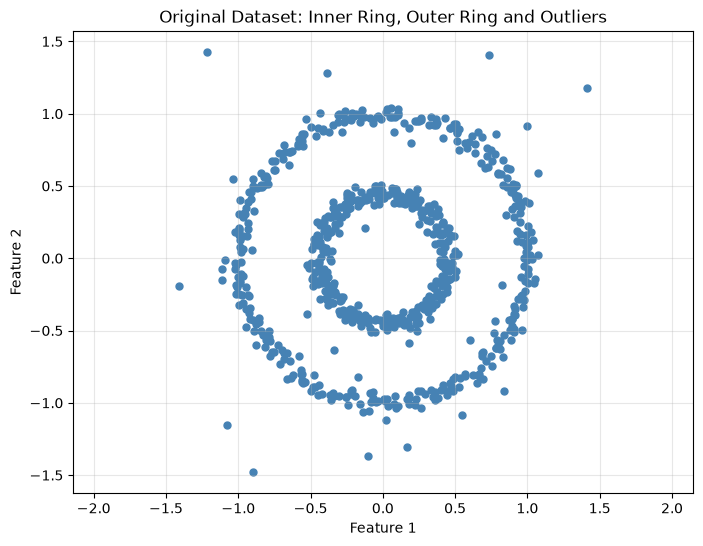

In [3]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X[:, 0],
    X[:, 1],
    s=25,
    color="steelblue"
)

plt.title("Original Dataset: Inner Ring, Outer Ring and Outliers")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.axis("equal")
plt.grid(alpha=0.3)

plt.show()

In [4]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Original data mean:")
print(X.mean(axis=0))

print("\nScaled data mean:")
print(X_scaled.mean(axis=0))

print("\nScaled data standard deviation:")
print(X_scaled.std(axis=0))

Original data mean:
[0.0052609  0.00182409]

Scaled data mean:
[-2.47723233e-17  6.34413157e-18]

Scaled data standard deviation:
[1. 1.]


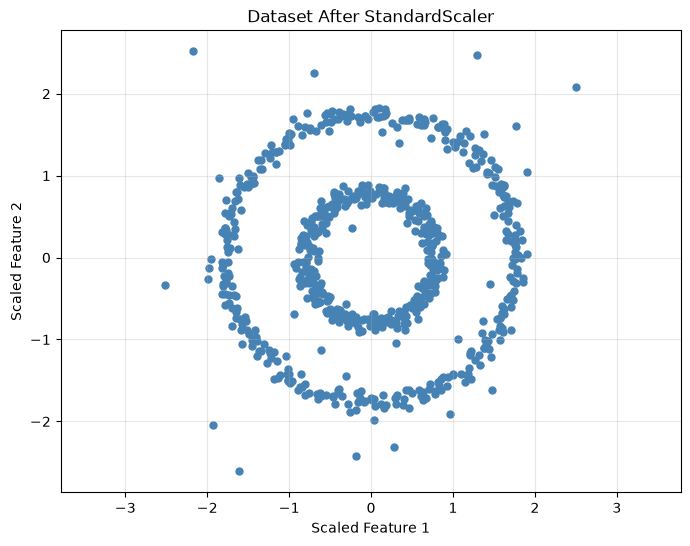

In [5]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    s=25,
    color="steelblue"
)

plt.title("Dataset After StandardScaler")
plt.xlabel("Scaled Feature 1")
plt.ylabel("Scaled Feature 2")

plt.axis("equal")
plt.grid(alpha=0.3)

plt.show()

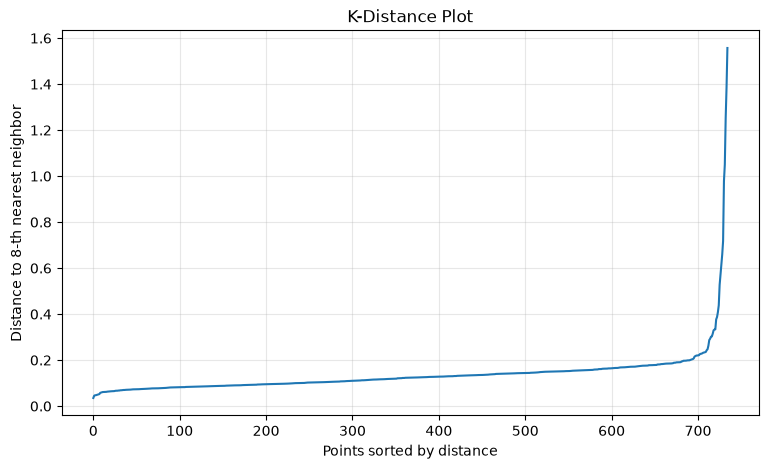

In [ ]:
min_samples = 8

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

k_distances = distances[:, -1]

k_distances_sorted = np.sort(k_distances)

plt.figure(figsize=(9, 5))

plt.plot(k_distances_sorted)

plt.title("K-Distance Plot")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}-th nearest neighbor")

plt.grid(alpha=0.3)

plt.show()

In [7]:
dbscan = DBSCAN(eps=0.25, min_samples=8)
labels = dbscan.fit_predict(X_scaled)

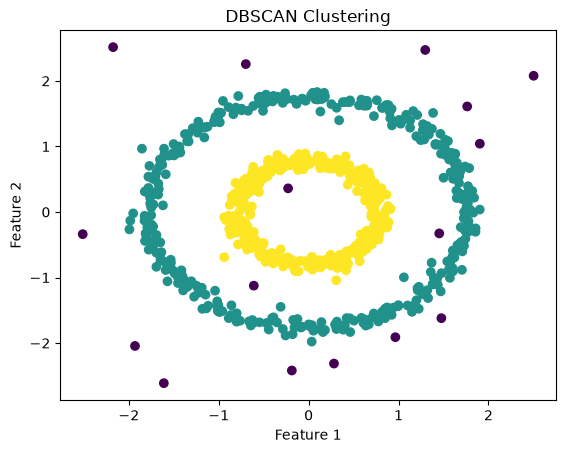

In [8]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap="viridis"
)

plt.title("DBSCAN Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
import numpy as np
import pandas as pd

from sklearn.cluster import DBSCAN
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import silhouette_score

param_grid = {
    "eps": [0.20, 0.25, 0.30],
    "min_samples": [5, 8, 10]
}

results = []

for params in ParameterGrid(param_grid):

    model = DBSCAN(**params)
    labels = model.fit_predict(X_scaled)

    mask = labels != -1
    X_filtered = X_scaled[mask]
    labels_filtered = labels[mask]

    n_clusters = len(set(labels_filtered))
    noise_count = np.sum(labels == -1)

    if n_clusters >= 2 and len(labels_filtered) > n_clusters:
        score = silhouette_score(
            X_filtered,
            labels_filtered
        )
    else:
        score = np.nan

    results.append({
        **params,
        "n_clusters": n_clusters,
        "noise_points": noise_count,
        "silhouette_score": score
    })

results_df = pd.DataFrame(results)

results_df.sort_values(
    by="silhouette_score",
    ascending=False
)

,eps,min_samples,n_clusters,noise_points,silhouette_score
2,0.20,10,3,22,0.222657
1,0.20,8,2,20,0.132776
0,0.20,5,2,19,0.132437
3,0.25,5,2,16,0.131665
4,0.25,8,2,16,0.131665
5,0.25,10,2,16,0.131665
6,0.30,5,2,13,0.131408
7,0.30,8,2,13,0.131408
8,0.30,10,2,13,0.131408


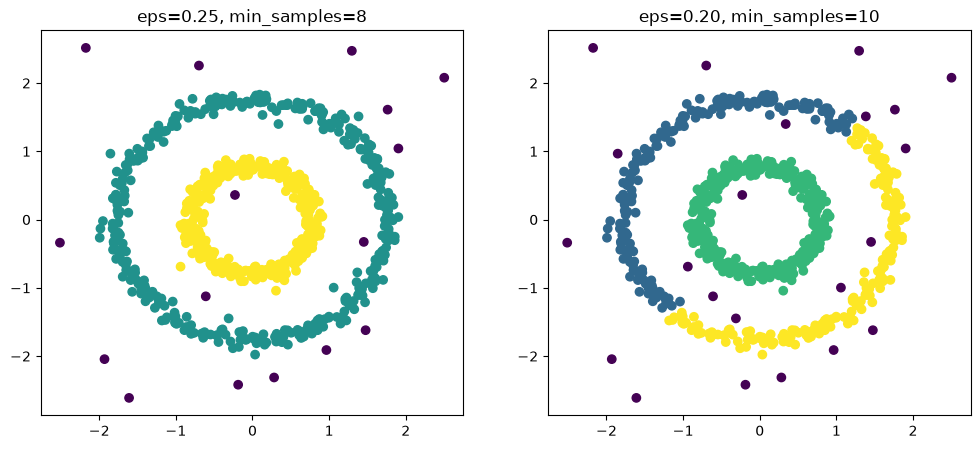

In [ ]:
dbscan_original = DBSCAN(
    eps=0.25,
    min_samples=8
)

labels_original = dbscan_original.fit_predict(X_scaled)


dbscan_best = DBSCAN(
    eps=0.20,
    min_samples=10
)

labels_best = dbscan_best.fit_predict(X_scaled)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels_original,
    cmap="viridis"
)

axes[0].set_title("eps=0.25, min_samples=8")


axes[1].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels_best,
    cmap="viridis"
)

axes[1].set_title("eps=0.20, min_samples=10")

plt.show()